# Data Preparation

### 1.โหลดข้อมูล

In [8]:
import pandas as pd

print("Loading data...")
classes = pd.read_csv('../data/raw/elliptic_txs_classes.csv')
edgelist = pd.read_csv('../data/raw/elliptic_txs_edgelist.csv')
features = pd.read_csv('../data/raw/elliptic_txs_features.csv', header=None)

Loading data...


### 2.ตั้งชื่อ Column ให้ features

In [9]:
col_names = ['txId'] + [f'feat_{i}' for i in range(166)]
features.columns = col_names

### 3.Merge ตาราง: เอา "เฉลย" (Classes) มาแปะใส่ "ข้อมูล" (Features)

In [10]:
print("Merging data...")
df_merged = pd.merge(features, classes, on='txId', how='left')

Merging data...


### 4. เปลี่ยนชื่อ Class ให้เข้าใจง่าย

In [11]:
df_clean = df_merged[df_merged['class'] != 'unknown'].copy()

# แปลง class เป็นตัวเลข (1=โจร, 0=ดี) เพื่อให้ Model ใช้ง่ายๆ
df_clean['label'] = df_clean['class'].apply(lambda x: 1 if x == '1' else 0)

### 5. เช็คของหน่อย

In [12]:
print("Original Size:", len(df_merged))
print("Cleaned Size (Known labels only):", len(df_clean))
print("Fraud Count:", df_clean['label'].sum())

Original Size: 203769
Cleaned Size (Known labels only): 46564
Fraud Count: 4545


### 6.เซฟลง folder processed

In [13]:
df_clean.to_csv('../data/processed/elliptic_bitcoin_dataset_v0.csv', index=False)
print("✅ Saved V0 dataset! Tell P2 to fetch it.")

✅ Saved V0 dataset! Tell P2 to fetch it.


# Graph Construction

In [14]:
%pip install networkx scipy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import networkx as nx
import matplotlib.pyplot as plt

### 1. สร้าง Graph จาก Edgelist

In [16]:
print("Building Graph...")
G = nx.from_pandas_edgelist(edgelist, source='txId1', target='txId2', create_using=nx.DiGraph())

print(f"Nodes: {G.number_of_nodes()}")
print(f"Edges: {G.number_of_edges()}")

Building Graph...
Nodes: 203769
Edges: 234355


### 2. ลองดึงเพื่อนบ้านของ Transaction สักอันดู (Sample)

In [17]:
sample_tx_id = edgelist.iloc[0]['txId1']
print(f"Check neighbors of: {sample_tx_id}")
print(list(G.successors(sample_tx_id))) # เงินโอนไปไหนต่อ

Check neighbors of: 230425980
[5530458]


### 3. (Optional) วาดกราฟย่อย

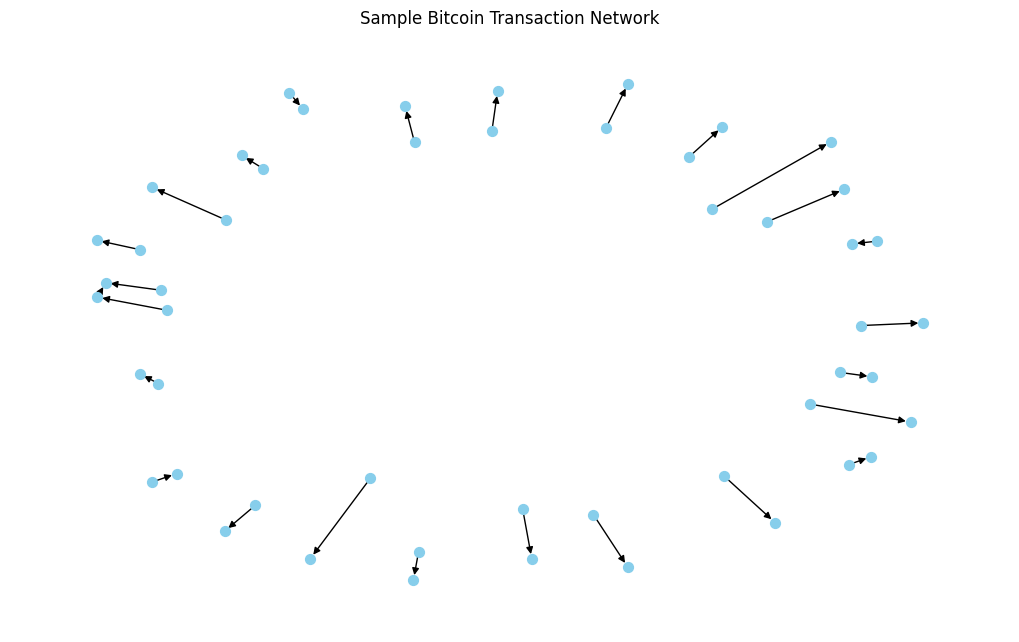

In [18]:
subgraph_nodes = list(G.nodes())[:50] # เอา 50 จุด
subgraph = G.subgraph(subgraph_nodes)
plt.figure(figsize=(10,6))
nx.draw(subgraph, with_labels=False, node_size=50, node_color='skyblue')
plt.title("Sample Bitcoin Transaction Network")
plt.show()

# Feature Engineering from Graph

### 1. สร้างกราฟจากข้อมูลทั้งหมด

In [19]:
print("Building full graph for feature extraction...")
G_full = nx.from_pandas_edgelist(edgelist, source='txId1', target='txId2', create_using=nx.DiGraph())

Building full graph for feature extraction...


### 2. คำนวณ In-degree และ Out-degree

In [20]:
# ผลลัพธ์จะเป็น Dictionary {txId: จำนวน}
print("Calculating degrees...")
in_degree_dict = dict(G_full.in_degree())
out_degree_dict = dict(G_full.out_degree())

Calculating degrees...


### 3. เอาค่าที่คำนวณได้ ยัดกลับเข้าไปใน DataFrame (df_clean)

In [21]:
# ใช้ map ในการจับคู่ txId กับค่า degree
df_clean['in_degree'] = df_clean['txId'].map(in_degree_dict)
df_clean['out_degree'] = df_clean['txId'].map(out_degree_dict)

### 4. เติม 0 ให้กับคนที่ไม่มีขาเข้า/ขาออก ป้องกันข้อมูลผิดพลาด

In [22]:
df_clean['in_degree'] = df_clean['in_degree'].fillna(0)
df_clean['out_degree'] = df_clean['out_degree'].fillna(0)

### 5. ลองเช็คดูข้อมูล

In [23]:
print("\nSample Data with Graph Features:")
print(df_clean[['txId', 'class', 'in_degree', 'out_degree']].head(10))


Sample Data with Graph Features:
         txId class  in_degree  out_degree
3   232438397     2        160           1
9   232029206     2         59           1
10  232344069     2          0           2
11   27553029     2          1           1
16    3881097     2          1           1
17  232457116     2          1           1
25  232412405     2          1           0
27  232470342     2          6           1
29  230550393     2         21           0
30  232051089     2          1           2


### 6.ลองดูสถิติหน่อยว่าโจร (label=1) มีพฤติกรรมต่างกับคนปกติไหม

In [24]:
print("\nAverage Degrees by Class:")
print(df_clean.groupby('label')[['in_degree', 'out_degree']].mean())


Average Degrees by Class:
       in_degree  out_degree
label                       
0       1.909398    1.185821
1       1.269967    0.741694


### 7 Save เป็นเวอร์ชัน 1 (V1)

In [25]:
df_clean.to_csv('../data/processed/elliptic_bitcoin_dataset_v1_graph.csv', index=False)
print("\n✅ Saved V1 dataset with graph features! Ready for P2.")


✅ Saved V1 dataset with graph features! Ready for P2.
